# Simulating First-Order Irregular Waves: A Comparison of Methods

This notebook demonstrates the generation of a linear irregular sea state from a JONSWAP spectrum. 
It highlights a common error in ocean wave simulation and contrasts it with the correct statistical approach outlined by Tucker et al. (1984).

## 1. The Fundamental Principle: Linear Superposition
Both methods rely on summing discrete, linear sinusoidal wave components:
$$\eta(t) = \sum_{i=1}^{N} A_i \cos(2\pi f_i t + \phi_i)$$

Where:
* $f_i$ are discrete frequencies.
* $\phi_i$ are random phases (uniformly distributed between $-\pi$ and $\pi$).
* $A_i$ are the component amplitudes. **How we define $A_i$ is where the two methods diverge.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Global Sea State Parameters ---
Hs = 5.0      # Significant wave height [m]
Tp = 10.0     # Peak wave period [s]
gamma = 3.3   # Peak enhancement factor
fp = 1.0 / Tp # Peak frequency [Hz]

# --- Global Numerical Parameters ---
T_repeat = 3 * 3600  # 3 hours [s]
df = 1.0 / T_repeat  # Frequency step [Hz]
f = np.arange(0.3 * fp, 3.0 * fp, df) # Frequency array
N = len(f)

dt = 0.1  # Time step [s]
t = np.arange(0, 600, dt) # 10-minute simulation

# --- JONSWAP Function ---
def jonswap(f, Hs, Tp, gamma):
    fp = 1.0 / Tp
    sigma = np.where(f <= fp, 0.07, 0.09)
    S_pm = (5.0 / 16.0) * (Hs**2) * (fp**4) * (f**-5) * np.exp(-1.25 * (f / fp)**-4)
    J = gamma ** np.exp(-0.5 * ((f - fp) / (sigma * fp))**2)
    A_gamma = 1 - 0.287 * np.log(gamma)
    return A_gamma * S_pm * J

# Calculate the theoretical spectrum
S_f = jonswap(f, Hs, Tp, gamma)

import os
os.makedirs('../output', exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 15,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 18,
    'axes.grid': True,
    'grid.alpha': 0.35,
})

## 2. Method 1: The "Common Error" (Deterministic Amplitudes)

This method assumes amplitudes are strictly defined by the spectral density:
$$A_i = \sqrt{2 S(f_i) \Delta f}$$

**Why it's flawed:** As noted by Tucker et al. (1984), a true Gaussian random process cannot have fixed amplitudes. This method constrains the variance and fails to realistically reproduce ocean wave "groupiness" (sequences of consecutive high waves).

In [2]:
np.random.seed(42) # Seed for reproducibility

# Deterministic calculation of amplitudes
A_det = np.sqrt(2 * S_f * df)

# Random phases
phases_det = np.random.uniform(-np.pi, np.pi, N)

# Generate Time Series
eta_det = np.zeros_like(t)
for i in range(N):
    eta_det += A_det[i] * np.cos(2 * np.pi * f[i] * t + phases_det[i])

# Verification
Hs_det_realized = 4 * np.std(eta_det)
print(f"Method 1 (Deterministic) Realized Hs: {Hs_det_realized:.2f} m")

Method 1 (Deterministic) Realized Hs: 5.00 m


## 3. Method 2: The Correct Statistical Approach (Rayleigh Amplitudes)

To properly simulate a Gaussian sea surface, amplitudes must be random variables. Tucker et al. (1984) detail that $A_i$ must be drawn from a Rayleigh distribution with a mean square value equal to the target energy: $E[A_i^2] = 2 S(f_i) \Delta f$.

In Python (`np.random.rayleigh(scale)`), the scale parameter $\sigma$ relates to the mean square by $2\sigma^2$. Thus:
$$Scale\ Parameter = \sqrt{S(f_i) \Delta f}$$

In [3]:
np.random.seed(42) # Use same seed to compare isolated amplitude effect

# Calculate scale parameter for Rayleigh distribution
scale_param = np.sqrt(S_f * df)

# Draw RANDOM amplitudes
A_ray = np.random.rayleigh(scale=scale_param)

# Random phases (same underlying distribution)
phases_ray = np.random.uniform(-np.pi, np.pi, N)

# Generate Time Series
eta_ray = np.zeros_like(t)
for i in range(N):
    eta_ray += A_ray[i] * np.cos(2 * np.pi * f[i] * t + phases_ray[i])

# Verification
Hs_ray_realized = 4 * np.std(eta_ray)
print(f"Method 2 (Rayleigh) Realized Hs: {Hs_ray_realized:.2f} m")

Method 2 (Rayleigh) Realized Hs: 4.30 m


## 4. Visual Comparison
Below, we compare the generated time series and the *realized* spectral energy density of our finite 10-minute records. Notice how Method 2's realized spectrum scatters realistically around the theoretical target, exactly as a real wave buoy's FFT would.

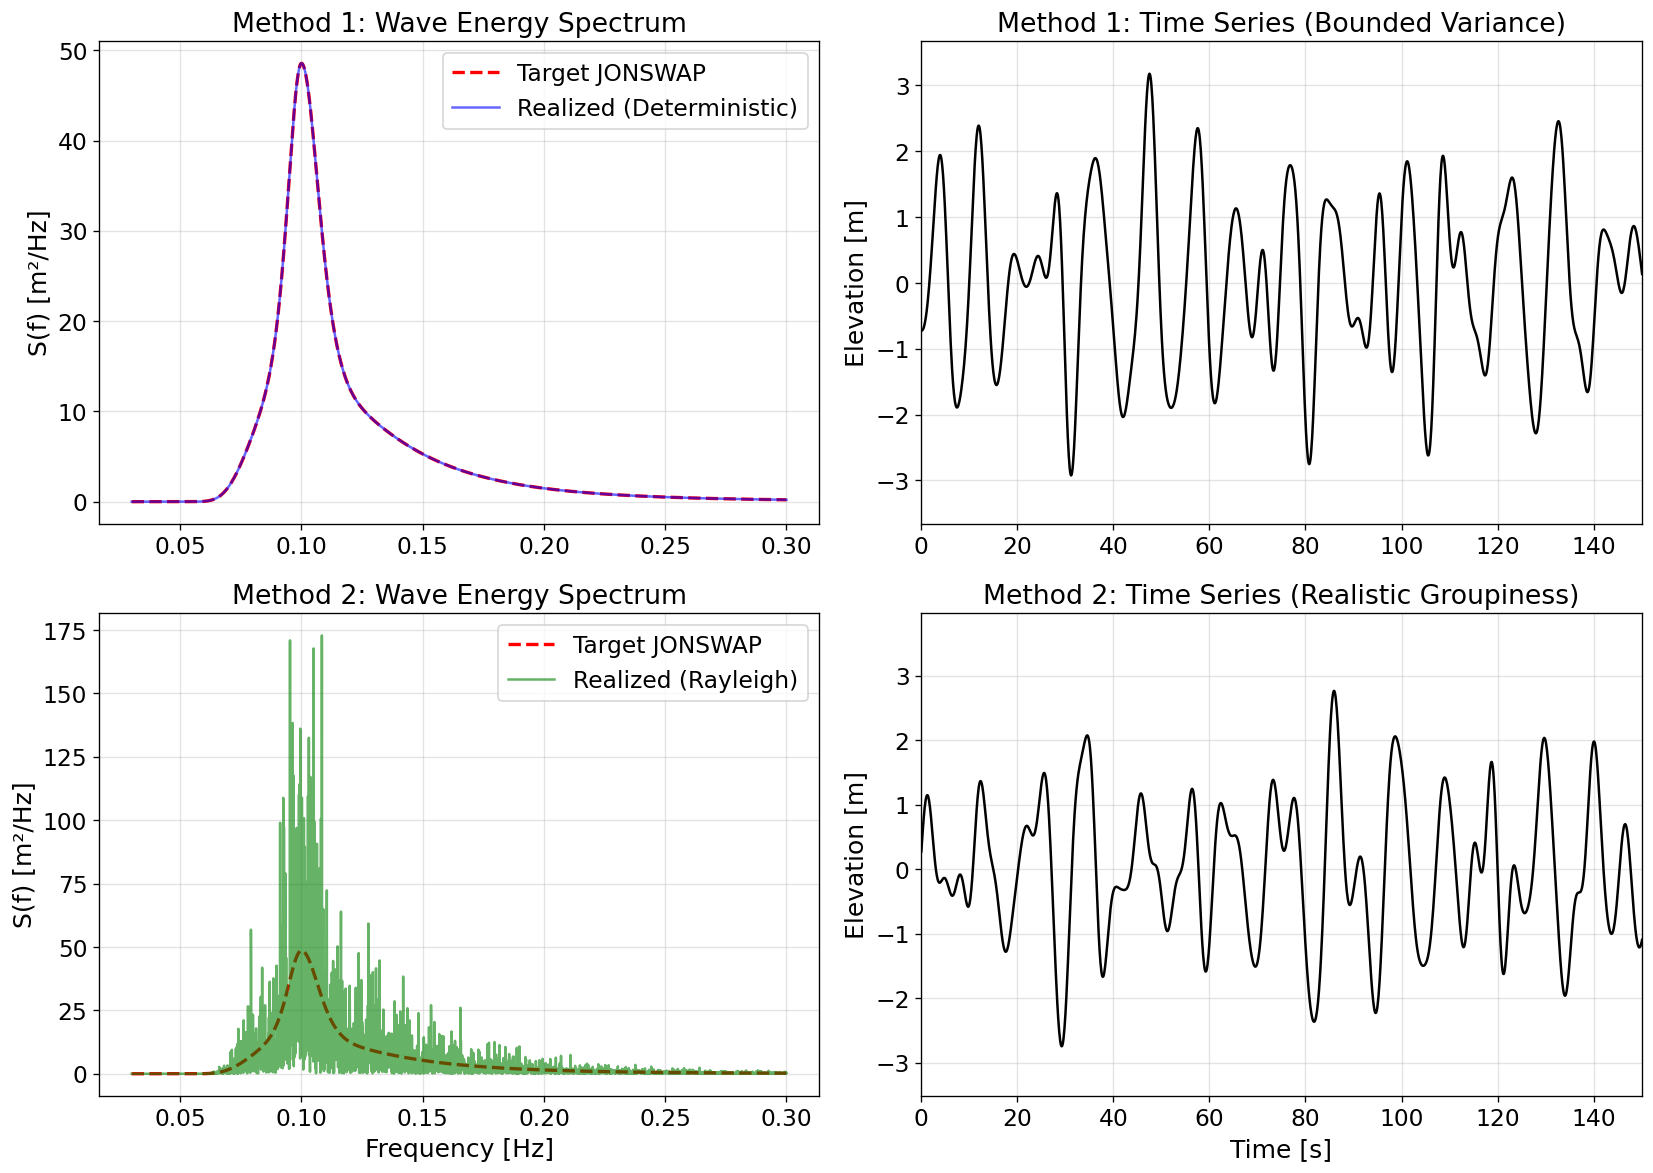

In [4]:
# Calculate realized spectra (S = A^2 / 2df)
S_det_realized = (A_det**2) / (2 * df)
S_ray_realized = (A_ray**2) / (2 * df)

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# --- Top Left: Spectra (Method 1) ---
axs[0, 0].plot(f, S_f, 'r--', linewidth=2, label='Target JONSWAP')
axs[0, 0].plot(f, S_det_realized, 'b-', alpha=0.6, label='Realized (Deterministic)')
axs[0, 0].set_title('Method 1: Wave Energy Spectrum')
axs[0, 0].set_ylabel(r'S(f) [m²/Hz]')
axs[0, 0].grid(True); axs[0, 0].legend()

# --- Top Right: Time Series (Method 1) ---
axs[0, 1].plot(t, eta_det, 'k-')
axs[0, 1].set_title('Method 1: Time Series (Bounded Variance)')
axs[0, 1].set_xlim(0, 150)
axs[0, 1].set_ylabel('Elevation [m]')
axs[0, 1].grid(True)

# --- Bottom Left: Spectra (Method 2) ---
axs[1, 0].plot(f, S_f, 'r--', linewidth=2, label='Target JONSWAP')
axs[1, 0].plot(f, S_ray_realized, 'g-', alpha=0.6, label='Realized (Rayleigh)')
axs[1, 0].set_title('Method 2: Wave Energy Spectrum')
axs[1, 0].set_xlabel('Frequency [Hz]')
axs[1, 0].set_ylabel(r'S(f) [m²/Hz]')
axs[1, 0].grid(True); axs[1, 0].legend()

# --- Bottom Right: Time Series (Method 2) ---
axs[1, 1].plot(t, eta_ray, 'k-')
axs[1, 1].set_title('Method 2: Time Series (Realistic Groupiness)')
axs[1, 1].set_xlabel('Time [s]')
axs[1, 1].set_xlim(0, 150)
axs[1, 1].set_ylabel('Elevation [m]')
axs[1, 1].grid(True)

plt.tight_layout()
fig.savefig('../output/wave_comparison.pdf', bbox_inches='tight')
plt.show()

---
### References
1. Tucker, M. J., Challenor, P. G., & Carter, D. J. T. (1984). *Numerical simulation of a random sea: a common error and its effect upon wave group statistics*. Applied Ocean Research, 6(2), 118-122.